# Análisis de la Bolsa de Palabras

Esta libreta tiene dos partes. La primera comprueba que la matriz del programa en C++ es correcta, comparándola contra `CountVectorizer` como en la libreta de la clase. La segunda dibuja los tiempos y el speedup que guarda el programa en `resultados/tiempos_<letra>.csv`.

Se corre desde la carpeta del proyecto después de correr `bolsaSerial` y `bolsaMPI` con la misma lista de urls, porque usa los libros que quedaron en `libros/`.

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer

## 1. Verificación contra CountVectorizer

La única diferencia con la libreta de la clase es el patrón de palabras: aquí se usa `[a-z0-9]{2,}`, que es la regla del programa (solo letras ASCII y dígitos). El patrón por omisión de sklearn también acepta guion bajo y letras con acento.

### Matriz del programa en C++

In [2]:
# La primera columna tiene el nombre de cada libro
matriz_serial = pd.read_csv("resultados/bolsa_serial.csv", index_col=0, keep_default_na=False)
k = matriz_serial.shape[0]
print(k, "libros y", matriz_serial.shape[1], "palabras")
matriz_serial

6 libros y 7358 palabras


,1513,1515,1524,abate,abatements,abbey,abed,abhorred,abhors,abide,...,youngest,your,yours,yourself,yourselves,youth,youthful,zeal,zone,zounds
libro,,,,,,,,,,,,,,,,,,,,,
pg1515,0,2,0,1,0,0,0,0,0,2,...,0,175,16,4,0,8,1,1,0,0
pg1513,2,0,0,1,0,1,2,1,1,0,...,1,104,3,5,0,6,3,0,0,2
pg1524,0,0,2,1,1,0,0,1,0,0,...,0,242,6,14,1,16,0,0,1,0
pg1515,0,2,0,1,0,0,0,0,0,2,...,0,175,16,4,0,8,1,1,0,0
pg1513,2,0,0,1,0,1,2,1,1,0,...,1,104,3,5,0,6,3,0,0,2
pg1524,0,0,2,1,1,0,0,1,0,0,...,0,242,6,14,1,16,0,0,1,0


### Matriz de CountVectorizer con los mismos libros

In [3]:
# Se leen los mismos archivos que conto el programa, en el mismo orden
corpus = []
for i in range(k):
    archivo = open("libros/libro_" + str(i) + ".txt", "r", encoding="utf-8")
    corpus.append(archivo.read())
    archivo.close()

count_vectorizer = CountVectorizer(lowercase=True, token_pattern=r"[a-z0-9]{2,}")
matriz_conteo = count_vectorizer.fit_transform(corpus).toarray()
vocabulario = count_vectorizer.get_feature_names_out()
matriz_sklearn = pd.DataFrame(matriz_conteo, columns=vocabulario, index=matriz_serial.index)
matriz_sklearn

,1513,1515,1524,abate,abatements,abbey,abed,abhorred,abhors,abide,...,youngest,your,yours,yourself,yourselves,youth,youthful,zeal,zone,zounds
libro,,,,,,,,,,,,,,,,,,,,,
pg1515,0,2,0,1,0,0,0,0,0,2,...,0,175,16,4,0,8,1,1,0,0
pg1513,2,0,0,1,0,1,2,1,1,0,...,1,104,3,5,0,6,3,0,0,2
pg1524,0,0,2,1,1,0,0,1,0,0,...,0,242,6,14,1,16,0,0,1,0
pg1515,0,2,0,1,0,0,0,0,0,2,...,0,175,16,4,0,8,1,1,0,0
pg1513,2,0,0,1,0,1,2,1,1,0,...,1,104,3,5,0,6,3,0,0,2
pg1524,0,0,2,1,1,0,0,1,0,0,...,0,242,6,14,1,16,0,0,1,0


### Comparación

In [4]:
mismas_columnas = list(matriz_serial.columns) == list(matriz_sklearn.columns)
print("Mismo vocabulario y en el mismo orden:", mismas_columnas)
if mismas_columnas:
    diferencias = (matriz_serial.values != matriz_sklearn.values).sum()
    print("Celdas diferentes:", diferencias)

Mismo vocabulario y en el mismo orden: True
Celdas diferentes: 0


### La matriz de MPI contra la serial

In [5]:
matriz_mpi = pd.read_csv("resultados/bolsa_mpi.csv", index_col=0, keep_default_na=False)
print("La matriz de MPI es igual a la serial:", matriz_mpi.equals(matriz_serial))

La matriz de MPI es igual a la serial: True


## 2. Tiempos

Cada corrida de `bolsaMPI` agrega un renglón a `resultados/tiempos_<letra>.csv` con el tiempo serial y el paralelo promedio de sus 10 repeticiones. Aquí se juntan los archivos de las dos computadoras y se agrupan las corridas de cada combinación de computadora, lista de libros y número de procesos.

La lista sale del nombre del archivo de urls: si contiene `grande` es la lista grande y si no es la chica. Así las corridas con las urls del espejo y con las oficiales caen en el mismo grupo, porque son los mismos libros.

In [6]:
tablas = []
for ruta in sorted(glob.glob("resultados/tiempos_*.csv")):
    # La letra de la computadora es lo que va entre "tiempos_" y ".csv"
    letra = os.path.basename(ruta)[len("tiempos_"):-len(".csv")]
    tabla = pd.read_csv(ruta)
    tabla["computadora"] = letra
    tablas.append(tabla)

tiempos = pd.concat(tablas, ignore_index=True)
tiempos["lista"] = np.where(tiempos["urls"].str.contains("grande"), "grande", "chica")
print("Corridas por computadora:")
print(tiempos["computadora"].value_counts().to_string())

Corridas por computadora:
J    40


Para cada combinación se calcula el promedio, el mínimo y el máximo. En las gráficas la barra es el promedio y la línea delgada va del mínimo al máximo, para que se vea cuánto varían las corridas.

In [7]:
resumen = tiempos.groupby(["computadora", "lista", "procesos"]).agg(
    corridas=("speedup", "size"),
    serial=("serial", "mean"), serial_min=("serial", "min"), serial_max=("serial", "max"),
    paralelo=("paralelo", "mean"), paralelo_min=("paralelo", "min"), paralelo_max=("paralelo", "max"),
    speedup=("speedup", "mean"), speedup_min=("speedup", "min"), speedup_max=("speedup", "max"),
).reset_index()
resumen.round(3)

,computadora,lista,procesos,corridas,serial,serial_min,serial_max,paralelo,paralelo_min,paralelo_max,speedup,speedup_min,speedup_max
0,J,chica,1,5,0.169,0.162,0.184,0.171,0.154,0.182,0.995,0.921,1.050
1,J,chica,2,5,0.170,0.156,0.204,0.117,0.104,0.143,1.452,1.417,1.504
2,J,chica,4,5,0.163,0.154,0.185,0.121,0.105,0.143,1.364,1.122,1.479
3,J,chica,8,5,0.175,0.154,0.209,0.125,0.113,0.161,1.416,1.226,1.807
4,J,grande,1,5,1.119,1.095,1.150,1.131,1.064,1.309,0.995,0.878,1.036
5,J,grande,2,5,1.095,1.069,1.118,0.744,0.661,0.969,1.502,1.113,1.668
6,J,grande,4,5,1.167,1.059,1.287,0.622,0.582,0.743,1.883,1.718,2.156
7,J,grande,8,5,1.106,1.043,1.145,0.615,0.596,0.650,1.800,1.728,1.893


### Estilo de las gráficas

Los mismos colores en todas: gris para el serial, azul para el paralelo y para José Luis, naranja para Miguel. Las imágenes se guardan en `graficas/` con la letra de la computadora al final, como en el primer proyecto.

In [8]:
os.makedirs("graficas", exist_ok=True)

COLOR_SERIAL = "#9a9890"
COLOR_PARALELO = "#2a78d6"
COLOR_COMPUTADORA = {"J": "#2a78d6", "M": "#eb6834"}
NOMBRE_COMPUTADORA = {"J": "José Luis", "M": "Miguel"}
NOMBRE_LISTA = {"chica": "Lista chica (3 obras, cada una dos veces)",
                "grande": "Lista grande (obras completas y 5 obras más)"}
COLOR_TEXTO = "#52514e"

plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b3ad",
    "axes.labelcolor": COLOR_TEXTO,
    "xtick.color": COLOR_TEXTO,
    "ytick.color": COLOR_TEXTO,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e6e4df",
    "axes.axisbelow": True,
    "legend.frameon": False,
})


# Dibuja barras con su linea de minimo a maximo y el valor arriba.
# La linea solo se dibuja si hay mas de una corrida.
def barras_con_rango(eje, x, promedio, minimo, maximo, corridas, ancho, color, nombre, formato):
    eje.bar(x, promedio, ancho, color=color, label=nombre)
    for i in range(len(x)):
        tope = promedio[i]
        if corridas[i] > 1:
            eje.plot([x[i], x[i]], [minimo[i], maximo[i]], color="#2b2b2b", linewidth=1.2)
            tope = maximo[i]
        eje.text(x[i], tope, formato.format(promedio[i]), ha="center", va="bottom", fontsize=8, color="#0b0b0b")


# Texto para el titulo: cuantas corridas se promediaron en cada caso
def texto_corridas(letra):
    corridas = resumen[resumen["computadora"] == letra]["corridas"]
    if corridas.min() == corridas.max():
        return " (promedio de " + str(int(corridas.min())) + " corridas por caso)"
    return " (promedio de " + str(int(corridas.min())) + " a " + str(int(corridas.max())) + " corridas por caso)"

### Tiempo serial contra tiempo paralelo

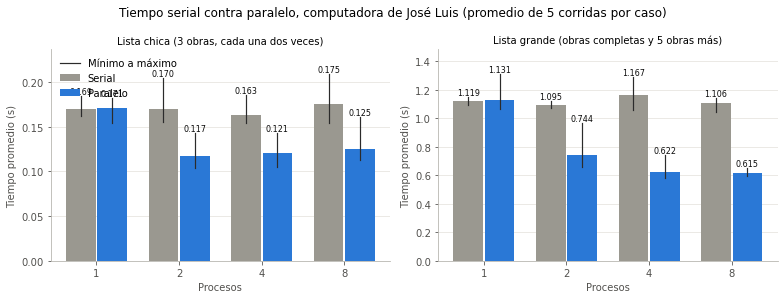

In [9]:
def graficar_tiempos(letra):
    fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2))
    for eje, lista in zip(ejes, ["chica", "grande"]):
        d = resumen[(resumen["computadora"] == letra) & (resumen["lista"] == lista)]
        x = np.arange(len(d))
        ancho = 0.38
        corridas = d["corridas"].values
        barras_con_rango(eje, x - ancho / 2, d["serial"].values, d["serial_min"].values, d["serial_max"].values,
                         corridas, ancho * 0.94, COLOR_SERIAL, "Serial", "{:.3f}")
        barras_con_rango(eje, x + ancho / 2, d["paralelo"].values, d["paralelo_min"].values, d["paralelo_max"].values,
                         corridas, ancho * 0.94, COLOR_PARALELO, "Paralelo", "{:.3f}")
        eje.set_xticks(x)
        eje.set_xticklabels(d["procesos"].values)
        eje.set_xlabel("Procesos")
        eje.set_ylabel("Tiempo promedio (s)")
        eje.set_title(NOMBRE_LISTA[lista], fontsize=10)
        eje.set_ylim(0, eje.get_ylim()[1] * 1.08)
    ejes[0].plot([], [], color="#2b2b2b", linewidth=1.2, label="Mínimo a máximo")
    ejes[0].legend(loc="upper left")
    fig.suptitle("Tiempo serial contra paralelo, computadora de " + NOMBRE_COMPUTADORA.get(letra, letra)
                 + texto_corridas(letra))
    fig.tight_layout()
    fig.savefig("graficas/tiempos_" + letra + ".png", dpi=150)
    plt.show()


for letra in sorted(resumen["computadora"].unique()):
    graficar_tiempos(letra)

### Speedup

El speedup de cada corrida es el tiempo serial entre el paralelo, medidos por el maestro en la misma corrida. La línea punteada marca la meta de 1.2x del enunciado y la gris marca 1x, donde el paralelo tarda lo mismo que el serial.

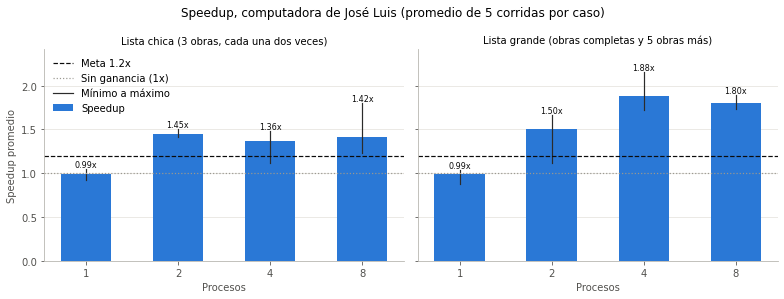

In [10]:
def lineas_de_referencia(eje):
    eje.axhline(1.2, color="#0b0b0b", linestyle="--", linewidth=1.2, label="Meta 1.2x")
    eje.axhline(1.0, color="#9a9890", linestyle=":", linewidth=1.2, label="Sin ganancia (1x)")


def graficar_speedup(letra):
    fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
    for eje, lista in zip(ejes, ["chica", "grande"]):
        d = resumen[(resumen["computadora"] == letra) & (resumen["lista"] == lista)]
        x = np.arange(len(d))
        barras_con_rango(eje, x, d["speedup"].values, d["speedup_min"].values, d["speedup_max"].values,
                         d["corridas"].values, 0.55, COLOR_COMPUTADORA.get(letra, COLOR_PARALELO), "Speedup", "{:.2f}x")
        lineas_de_referencia(eje)
        eje.set_xticks(x)
        eje.set_xticklabels(d["procesos"].values)
        eje.set_xlabel("Procesos")
        eje.set_title(NOMBRE_LISTA[lista], fontsize=10)
    ejes[0].set_ylabel("Speedup promedio")
    ejes[0].set_ylim(0, max(2.0, resumen["speedup_max"].max() * 1.12))
    ejes[0].plot([], [], color="#2b2b2b", linewidth=1.2, label="Mínimo a máximo")
    ejes[0].legend(loc="upper left")
    fig.suptitle("Speedup, computadora de " + NOMBRE_COMPUTADORA.get(letra, letra) + texto_corridas(letra))
    fig.tight_layout()
    fig.savefig("graficas/speedup_" + letra + ".png", dpi=150)
    plt.show()


for letra in sorted(resumen["computadora"].unique()):
    graficar_speedup(letra)

## 3. Comparación entre computadoras

Speedup de la lista grande en las dos computadoras. Cada una probó los números de procesos que tienen sentido para sus núcleos, así que el eje muestra todos y falta una barra donde una computadora no corrió ese caso. Esta gráfica solo se dibuja cuando ya existe `resultados/tiempos_M.csv`.

In [11]:
if not os.path.exists("resultados/tiempos_M.csv"):
    print("Todavía no está resultados/tiempos_M.csv: la comparación se dibuja cuando Miguel suba sus tiempos.")
else:
    grande = resumen[resumen["lista"] == "grande"]
    procesos = sorted(grande["procesos"].unique())
    x = np.arange(len(procesos))
    ancho = 0.38
    fig, eje = plt.subplots(figsize=(8, 4.2))
    for desplazamiento, letra in [(-ancho / 2, "J"), (ancho / 2, "M")]:
        d = grande[grande["computadora"] == letra].set_index("procesos")
        posiciones = []
        for i in range(len(procesos)):
            if procesos[i] in d.index:
                posiciones.append(i)
        p = [procesos[i] for i in posiciones]
        barras_con_rango(eje, x[posiciones] + desplazamiento, d.loc[p, "speedup"].values, d.loc[p, "speedup_min"].values,
                         d.loc[p, "speedup_max"].values, d.loc[p, "corridas"].values, ancho * 0.94,
                         COLOR_COMPUTADORA[letra], NOMBRE_COMPUTADORA[letra], "{:.2f}x")
    lineas_de_referencia(eje)
    eje.set_xticks(x)
    eje.set_xticklabels(procesos)
    eje.set_xlabel("Procesos")
    eje.set_ylabel("Speedup promedio")
    eje.set_ylim(0, max(2.0, grande["speedup_max"].max() * 1.12))
    eje.plot([], [], color="#2b2b2b", linewidth=1.2, label="Mínimo a máximo")
    eje.legend(loc="upper left", ncol=2)
    eje.set_title("Speedup con la lista grande en las dos computadoras")
    fig.tight_layout()
    fig.savefig("graficas/comparacion_U.png", dpi=150)
    plt.show()

Todavía no está resultados/tiempos_M.csv: la comparación se dibuja cuando Miguel suba sus tiempos.
